<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Applied Nueral Networks: Projekt </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# Vorhersage einer gedämpften Schwingung mittels Reservoir Computing

In diesem Projekt werden gedämpfte Schwingungen mithilfe eines **Echo State Networks (ESN)** vorhergesagt. Die Schwingungen werden künstlich erzeugt und decken einen breiten Bereich von Amplituden, Dämpfungen und Frequenzen ab.

---

## Aufbau

### 1. Datenerzeugung

Zuerst werden verschiedene gedämpfte Schwingungen erzeugt. Sie dienen als Trainings- und Testdaten. Die mathematische Grundlage ist die gedämpfte Sinusfunktion:

$$y(t) = A \cdot e^{-\alpha t} \cdot \sin(\omega t + \varphi)$$

| Parameter | Symbol | Bedeutung |
|---|---|---|
| Amplitude | $A$ | Maximale Auslenkung |
| Dämpfungskonstante | $\alpha$ | Wie schnell die Schwingung abklingt |
| Kreisfrequenz | $\omega$ | Wie schnell die Schwingung schwingt |
| Phase | $\varphi$ | Verschiebung des Startzeitpunkts |

Die **Trainingsdaten** werden strukturiert erzeugt: Die Parameter werden systematisch über ihren Wertebereich verteilt, damit alle relevanten Kombinationen abgedeckt sind.

Die **Testdaten** werden vollständig zufällig erzeugt (anderer Seed), um zu prüfen, ob das Modell auf ungesehenen Schwingungen generalisiert.

### 2. Netzwerk erstellen und trainieren

Das ESN wird in Notebook `02ANN_Training.ipynb` implementiert und trainiert. Nur die Ausgabeschicht `W_out` wird durch Backpropagation angepasst. Das Reservoir bleibt zufällig und fest.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os


## 1. Imports

Die folgenden Bibliotheken werden für die Datenerzeugung und Visualisierung benötigt.

In [10]:

def generate_diverse_oscillations(n=25):
    """Generiert n Schwingungen mit guter Parameterabdeckung"""
    np.random.seed(42)
    oscillations = []
    
    # Kombiniere verschiedene Bereiche
    for i in range(n):
        # Amplitude: Gleichmäßig verteilt
        A = 0.5 + (1.5 / n) * i + np.random.uniform(-0.1, 0.1)
        
        # Dämpfung: Mische schwach/mittel/stark
        if i % 3 == 0:
            α = np.random.uniform(0.01, 0.05)  # schwach
        elif i % 3 == 1:
            α = np.random.uniform(0.05, 0.10)  # mittel
        else:
            α = np.random.uniform(0.10, 0.15)  # stark
        
        # Frequenz: Gleichmäßig verteilt
        ω = (1.0 + (3.0 / n) * i) * np.pi + np.random.uniform(-0.2, 0.2) * np.pi
        
        # Phase: Random
        φ = np.random.uniform(0, 2*np.pi)
        
        t = np.linspace(0, 20, 1000)
        y = A * np.exp(-α * t) * np.sin(ω * t + φ)
        
        oscillations.append({
            't': t,
            'y': y,
            'params': {'A': A, 'α': α, 'ω': ω, 'φ': φ}
        })
    
    return oscillations

oscillations = generate_diverse_oscillations(25)

print("25 Trainingsschwingungen generiert.")

if not os.path.exists('data'):
    os.makedirs('data')
np.save('data/oscillations.npy', oscillations)


25 Trainingsschwingungen generiert.


## 2. Trainingsdaten erzeugen

Die Funktion `generate_diverse_oscillations` erzeugt 25 Schwingungen mit **strukturiert verteilten Parametern**. Ziel ist eine möglichst breite Abdeckung des Parameterraums:

- **Amplitude** $A$: gleichmässig von 0.5 bis 2.0 verteilt
- **Dämpfung** $\alpha$: abwechselnd schwach (0.01–0.05), mittel (0.05–0.10) und stark (0.10–0.15)
- **Frequenz** $\omega$: gleichmässig von $\pi$ bis $4\pi$ verteilt
- **Phase** $\varphi$: zufällig aus $[0, 2\pi]$

Jede Schwingung wird über $t \in [0, 20]$ mit 1000 Zeitschritten abgetastet und als Dictionary mit den Feldern `t`, `y` und `params` gespeichert. Die Daten werden unter `data/oscillations.npy` gespeichert.

In [11]:
def generate_test_oscillations(n=25, seed=99):
    """
    Generiert n Test-Schwingungen vollständig zufällig.

    Gleiche Wertebereiche wie Trainingsdaten, aber rein zufällig
    (kein strukturiertes Abtasten des Parameterraums).
    seed=99 → reproduzierbar und verschieden von den Trainingsdaten.
    """
    rng = np.random.RandomState(seed)
    oscillations_test = []

    for i in range(n):
        # Alle Parameter vollständig zufällig aus den gleichen Bereichen
        A = rng.uniform(0.5, 2.0)
        α = rng.uniform(0.01, 0.15)
        ω = rng.uniform(1.0, 4.0) * np.pi
        φ = rng.uniform(0, 2 * np.pi)

        t = np.linspace(0, 20, 1000)
        y = A * np.exp(-α * t) * np.sin(ω * t + φ)

        oscillations_test.append({
            't': t,
            'y': y,
            'params': {'A': A, 'α': α, 'ω': ω, 'φ': φ}
        })

    return oscillations_test

oscillations_test = generate_test_oscillations(25)

print(f"Testdaten generiert: {len(oscillations_test)} Schwingungen")
print(f"Beispiel-Parameter: {oscillations_test[0]['params']}")
if not os.path.exists('data'):
    os.makedirs('data') 
    np.save('data/oscillations_test.npy', oscillations_test)
else: 
    np.save('data/oscillations_test.npy', oscillations_test)
print("Testdaten gespeichert unter: data/oscillations_test.npy")

Testdaten generiert: 25 Schwingungen
Beispiel-Parameter: {'A': 1.5084178379461877, 'α': 0.07833097589368171, 'ω': 10.921701376564792, 'φ': 0.19758348069743045}
Testdaten gespeichert unter: data/oscillations_test.npy


## 3. Testdaten erzeugen

Die Testdaten werden **vollständig zufällig** aus denselben Wertebereichen wie die Trainingsdaten generiert. Der feste Seed `99` stellt sicher, dass die Testdaten reproduzierbar und von den Trainingsdaten verschieden sind.

Der Unterschied zur Trainingsgenerierung: Es gibt keine strukturierte Verteilung der Parameter. Das Modell bekommt damit Schwingungen zu sehen, die es im Training nicht in dieser Form gesehen hat, was eine realistische Einschätzung der Generalisierungsfähigkeit erlaubt.

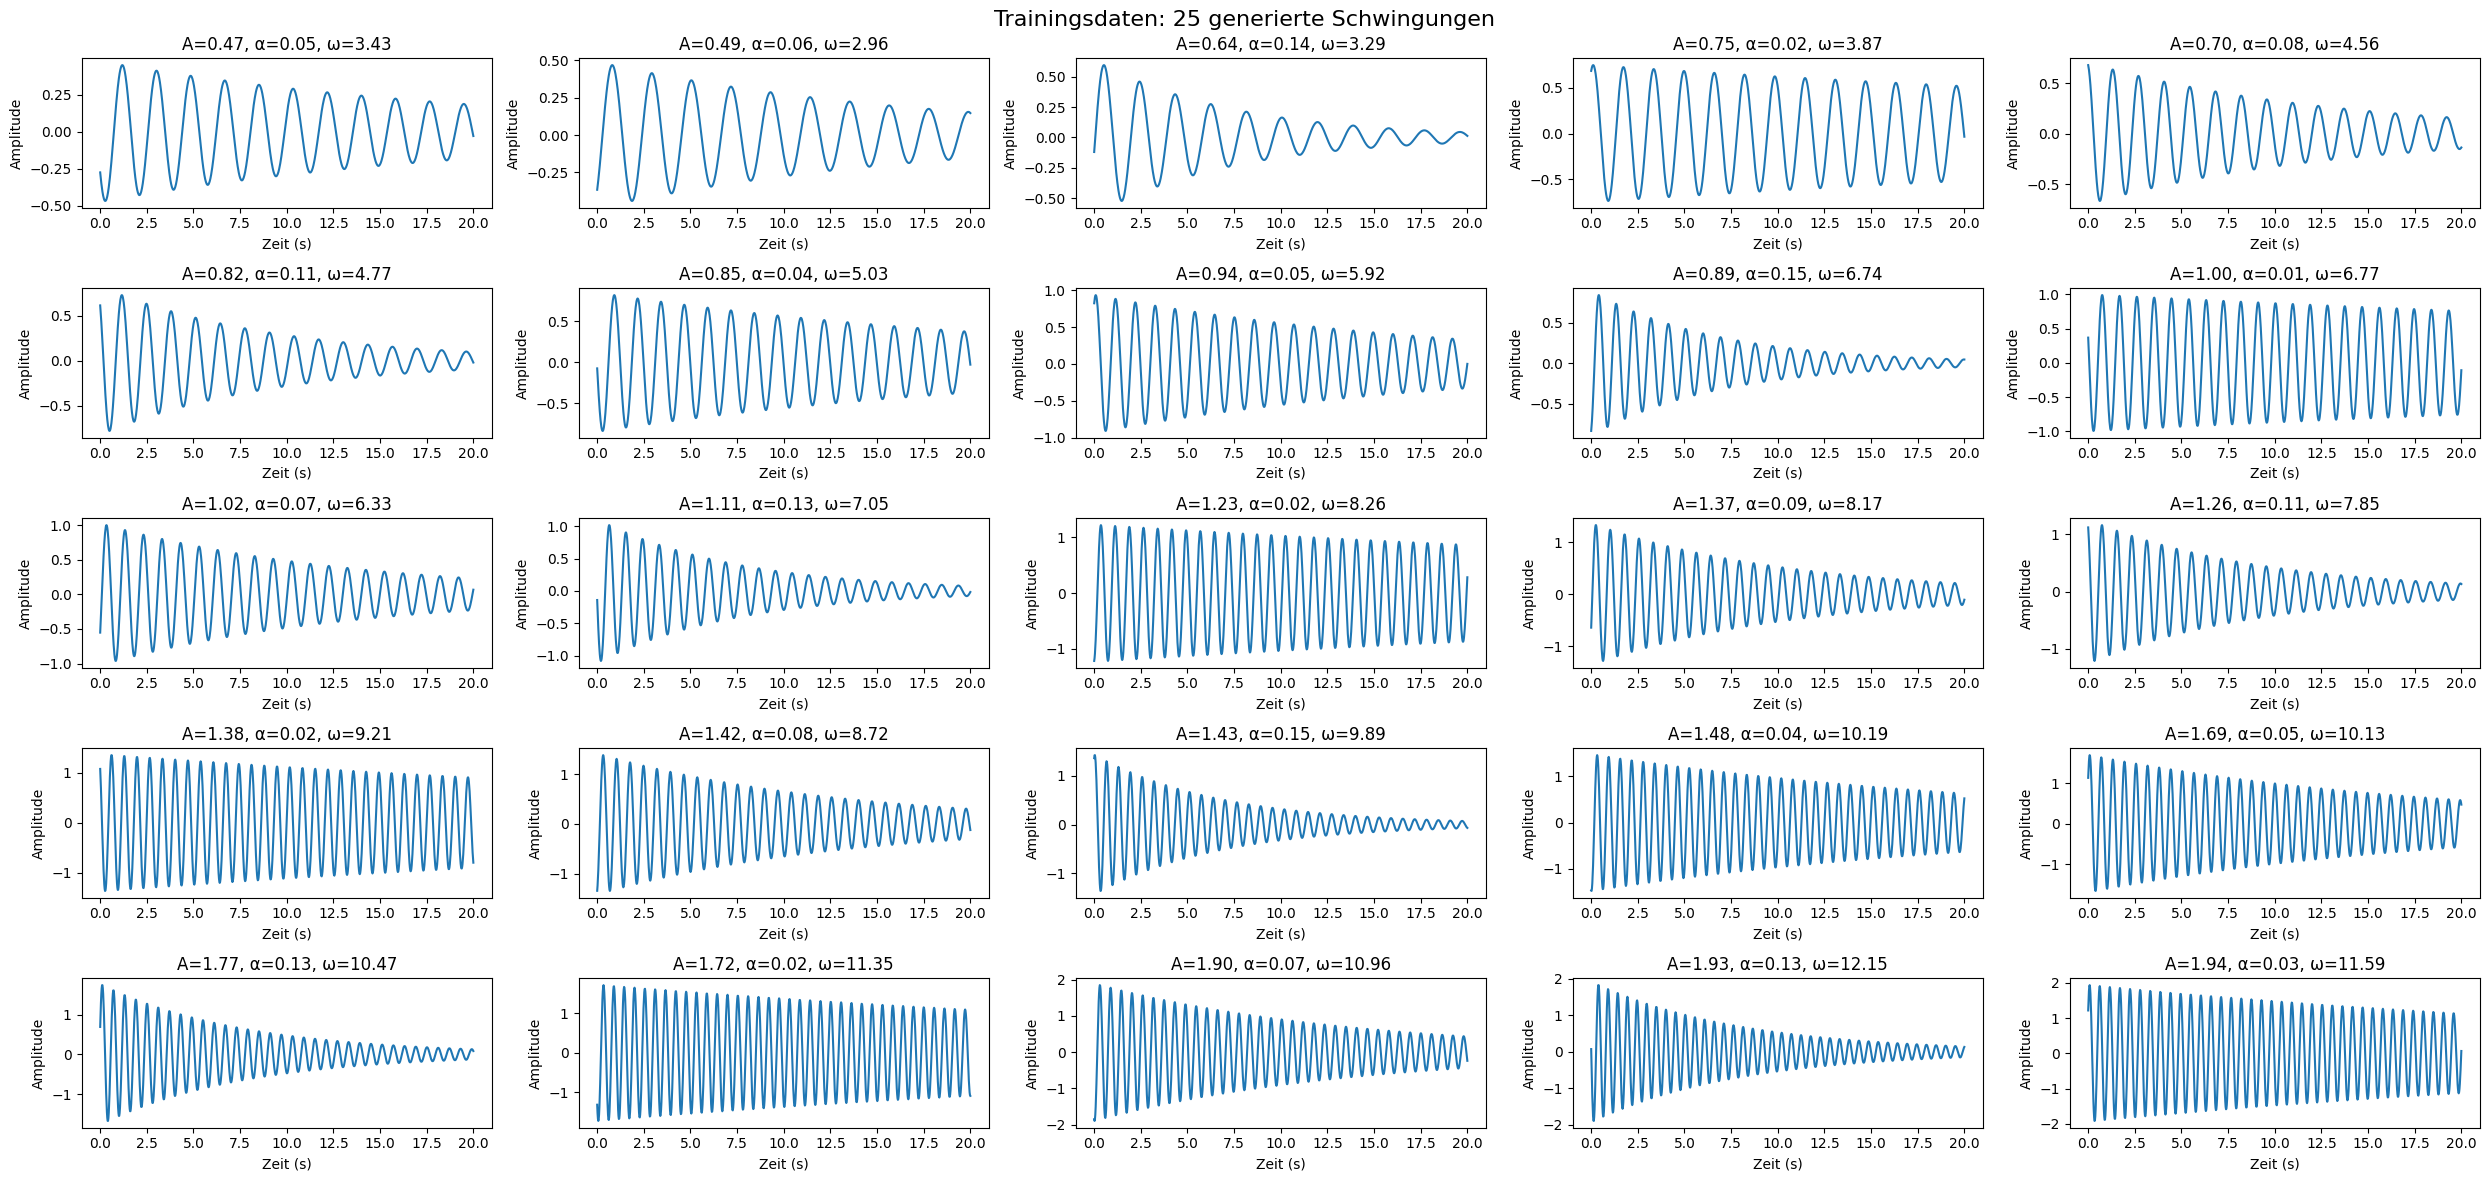

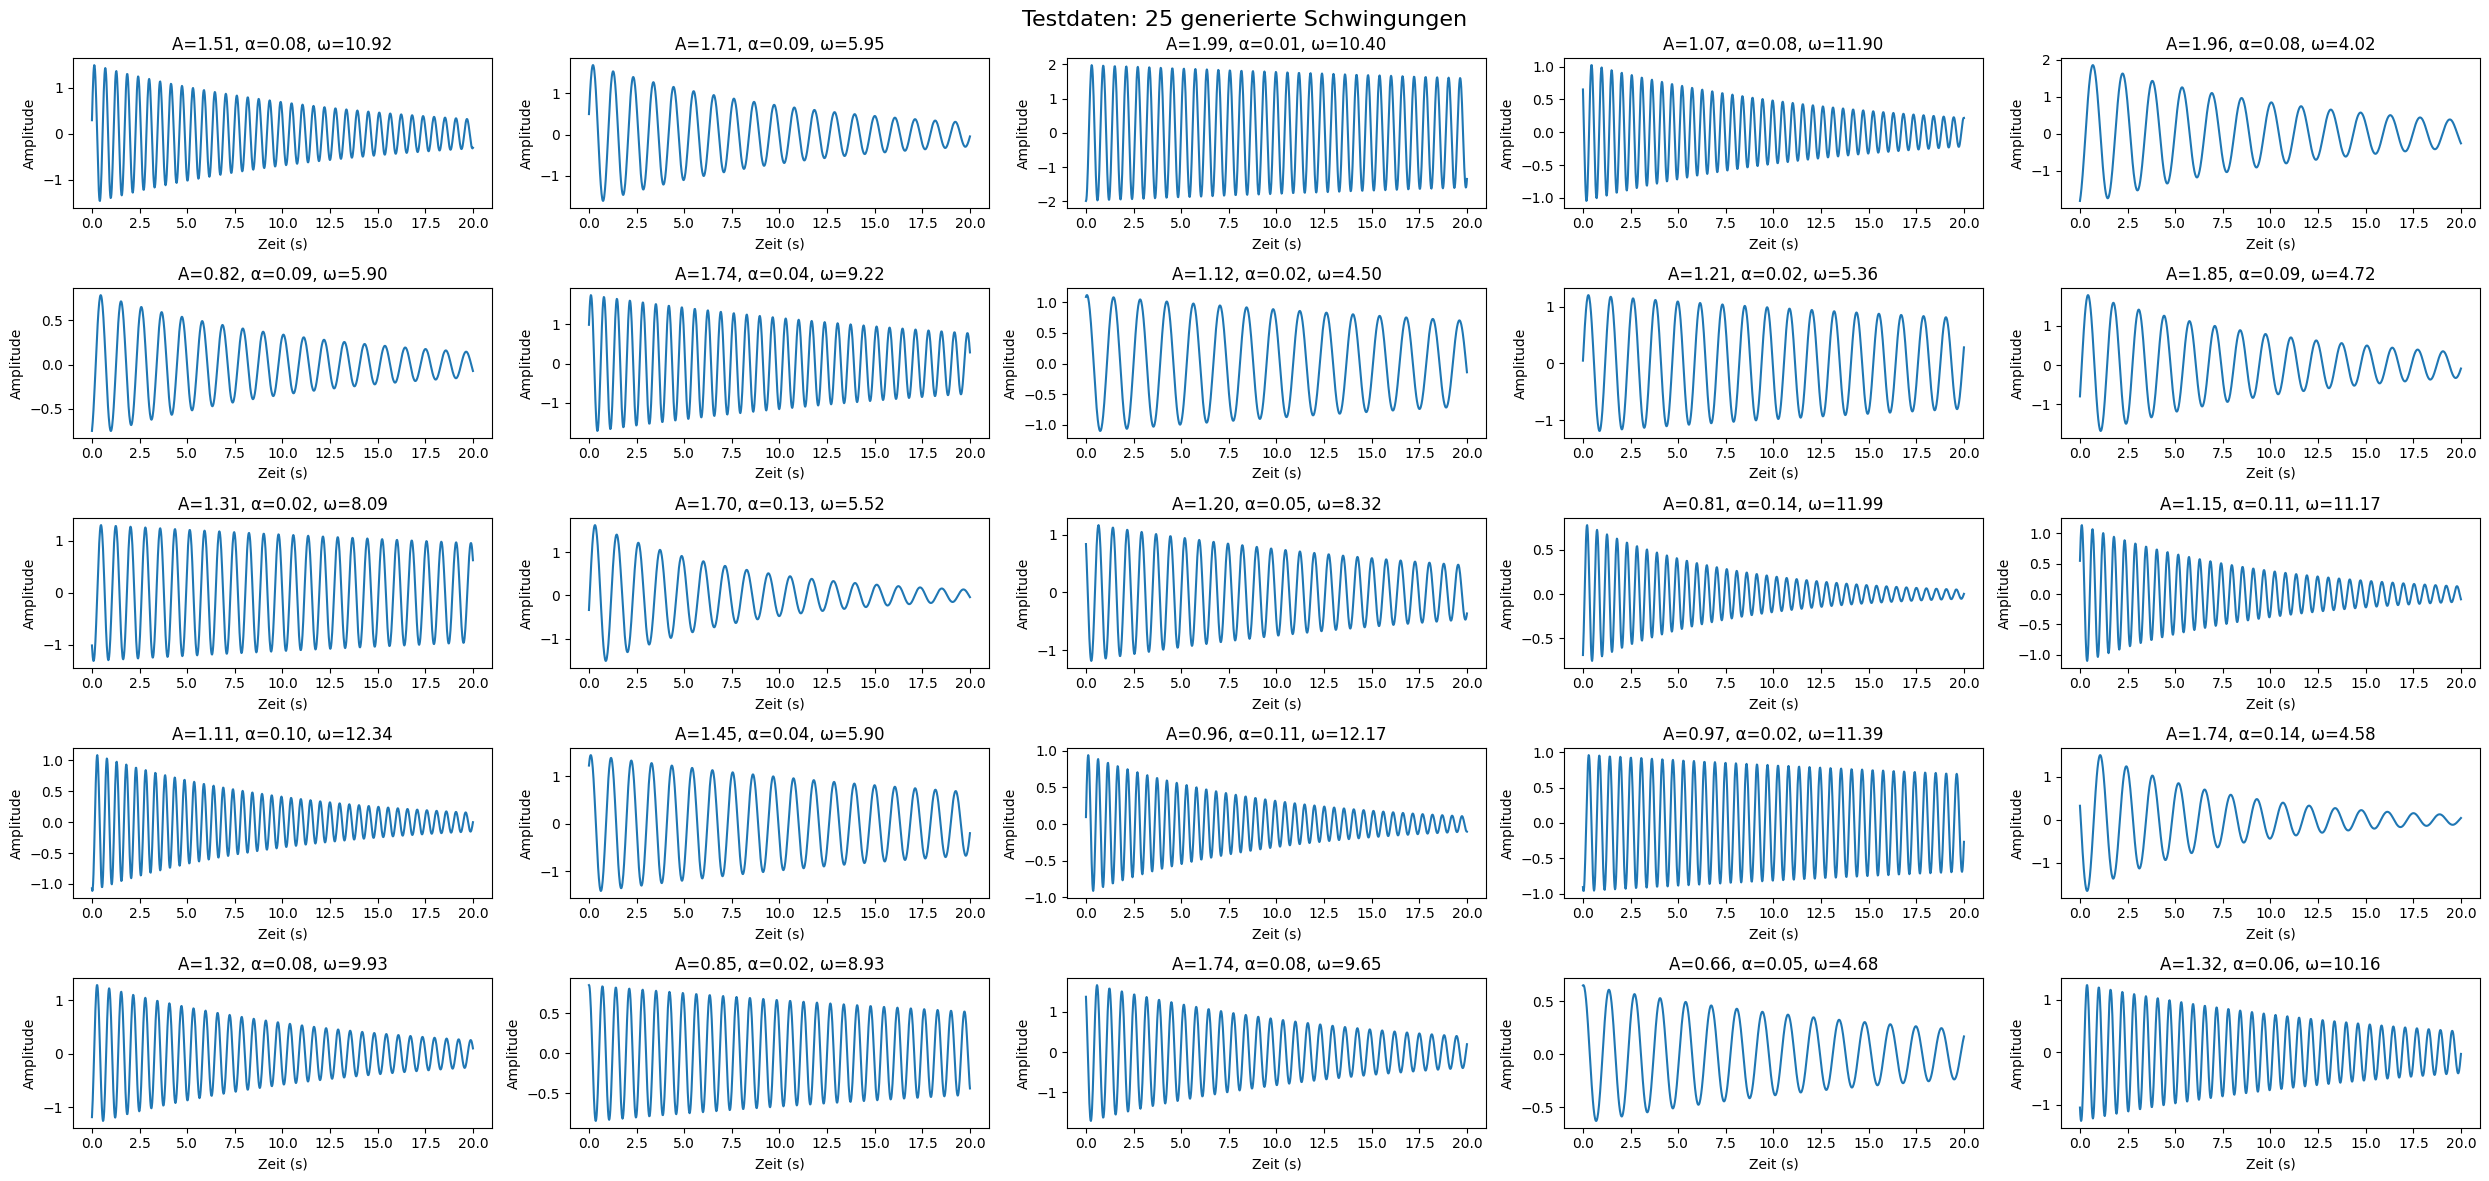

In [12]:
def plot_oscillations(oscillations, testdata: bool = False):
    """Plottet die generierten Schwingungen"""
    fig, axes = plt.subplots(5, 5, figsize=(25, 12))
    if testdata:
        fig.suptitle("Testdaten: 25 generierte Schwingungen", fontsize=16)
    else:
        fig.suptitle("Trainingsdaten: 25 generierte Schwingungen", fontsize=16)
    axes = axes.flatten()
    
    for i, osc in enumerate(oscillations):
        axes[i].plot(osc['t'], osc['y'])
        axes[i].set_title(f"A={osc['params']['A']:.2f}, α={osc['params']['α']:.2f}, ω={osc['params']['ω']:.2f}")
        axes[i].set_xlabel('Zeit (s)')
        axes[i].set_ylabel('Amplitude')
    
    plt.tight_layout()
    plt.show()

plot_oscillations(oscillations)
plot_oscillations(oscillations_test, True)
